In [12]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [13]:
file_path = r"G:\VAC Data Science\VAC Mini project\traffic.csv"

df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

# Fix a possible spelling variation in the CSV
df = df.rename(columns={"Juction": "Junction"})

df["DateTime"] = pd.to_datetime(df["DateTime"])
df["Junction"] = pd.to_numeric(df["Junction"]).astype(int)
df["Vehicles"] = pd.to_numeric(df["Vehicles"])

df = (
    df.drop_duplicates()
      .dropna(subset=["DateTime", "Junction", "Vehicles"])
      .sort_values("DateTime")
      .reset_index(drop=True)
)

# Friendly display names. Replace these if you learn the actual location names.
junction_names = {
    1: "Chennai ",
    2: "Pondicherry ",
    3: "ECR ",
    4: "Chengalpattu"
}

# Add a display-only column; keep Junction for the model
df["Location"] = df["Junction"].map(junction_names)

print("Columns:", df.columns.tolist())
print("Dataset size:", df.shape)
print("Available junctions:", sorted(df["Junction"].unique()))

display(df[["DateTime", "Junction", "Location", "Vehicles"]].head())

Columns: ['DateTime', 'Junction', 'Vehicles', 'ID', 'Location']
Dataset size: (48120, 5)
Available junctions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,DateTime,Junction,Location,Vehicles
0,2015-11-01 00:00:00,1,Chennai,15
1,2015-11-01 00:00:00,2,Pondicherry,6
2,2015-11-01 00:00:00,3,ECR,9
3,2015-11-01 01:00:00,3,ECR,7
4,2015-11-01 01:00:00,1,Chennai,13


In [14]:
location_summary = (
    df.groupby("Location")["Vehicles"]
      .agg(["mean", "median", "max", "std"])
      .round(2)
)

display(location_summary)

,mean,median,max,std
Location,,,,
Chengalpattu,7.25,7.0,36,3.52
Chennai,45.05,40.0,156,23.01
ECR,13.69,11.0,180,10.44
Pondicherry,14.25,13.0,48,7.40


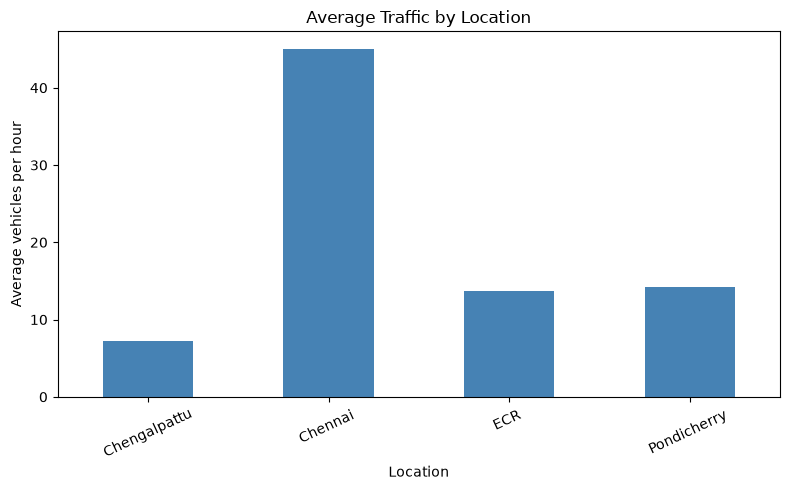

In [15]:
average_by_location = df.groupby("Location")["Vehicles"].mean()

average_by_location.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue",
    title="Average Traffic by Location"
)

plt.xlabel("Location")
plt.ylabel("Average vehicles per hour")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

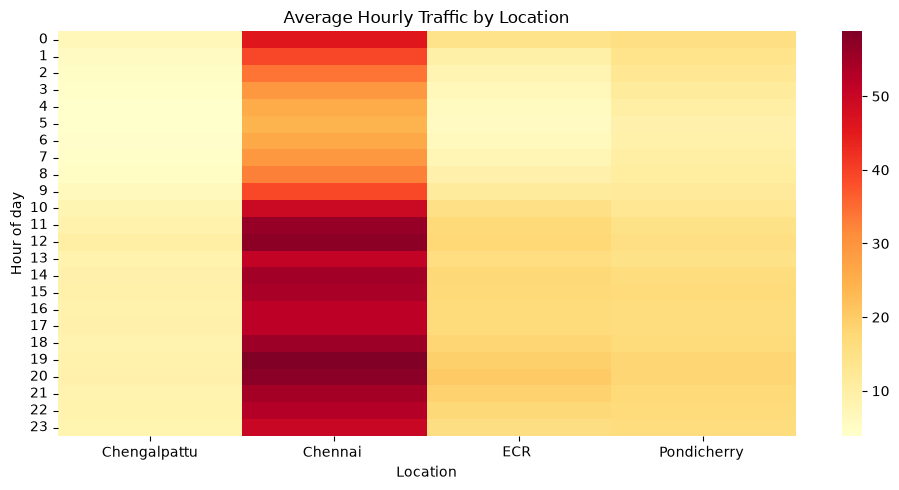

In [16]:
df["Hour"] = df["DateTime"].dt.hour

hourly_by_location = df.pivot_table(
    index="Hour",
    columns="Location",
    values="Vehicles",
    aggfunc="mean"
)

plt.figure(figsize=(10, 5))
sns.heatmap(hourly_by_location, cmap="YlOrRd")
plt.title("Average Hourly Traffic by Location")
plt.xlabel("Location")
plt.ylabel("Hour of day")
plt.tight_layout()
plt.show()

In [17]:
df["Hour"] = df["DateTime"].dt.hour
df["DayOfWeek"] = df["DateTime"].dt.dayofweek
df["Month"] = df["DateTime"].dt.month
df["DayOfMonth"] = df["DateTime"].dt.day

# Location is represented by Junction ID in the model
features = ["Junction", "Hour", "DayOfWeek", "Month", "DayOfMonth"]

X = pd.get_dummies(
    df[features],
    columns=["Junction"],
    dtype=int
)

y = df["Vehicles"]

# Split by time: earlier records train the model; later records test it
split_position = int(len(df) * 0.8)
cutoff_time = df.loc[split_position, "DateTime"]

train_mask = df["DateTime"] < cutoff_time
test_mask = df["DateTime"] >= cutoff_time

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]
y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

train_df = df.loc[train_mask].copy()

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training complete.")


Model training complete.


In [18]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Mean absolute error:", round(mae, 2), "vehicles")
print("Root mean squared error:", round(rmse, 2), "vehicles")

Mean absolute error: 13.97 vehicles
Root mean squared error: 20.36 vehicles


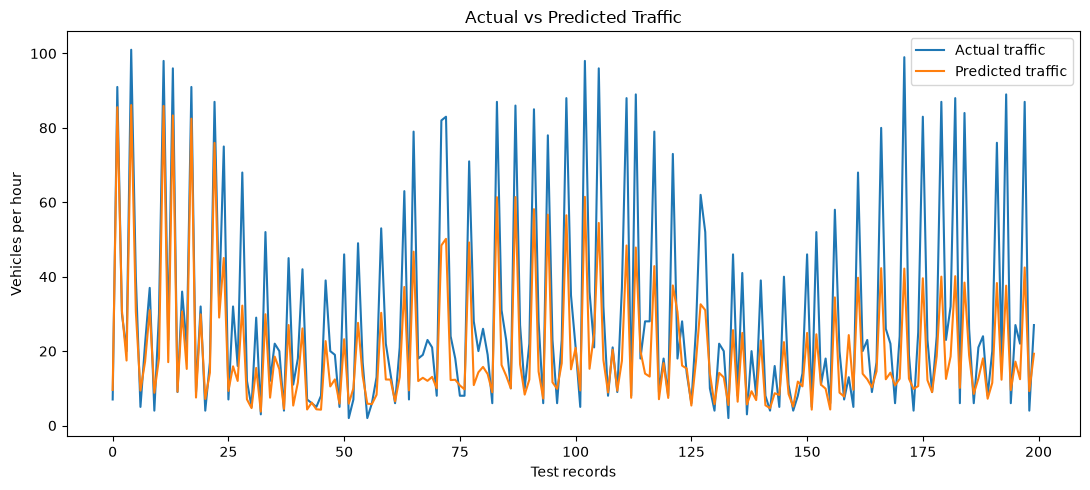

In [19]:
number_to_plot = min(200, len(y_test))

plt.figure(figsize=(11, 5))
plt.plot(y_test.iloc[:number_to_plot].to_numpy(), label="Actual traffic")
plt.plot(predictions[:number_to_plot], label="Predicted traffic")
plt.title("Actual vs Predicted Traffic")
plt.xlabel("Test records")
plt.ylabel("Vehicles per hour")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
alert_limits = {}

for junction, group in train_df.groupby("Junction"):
    low_limit = group["Vehicles"].quantile(1 / 3)
    high_limit = group["Vehicles"].quantile(2 / 3)

    alert_limits[int(junction)] = (
        float(low_limit),
        float(high_limit)
    )

print(alert_limits)

{1: (29.0, 46.0), 2: (9.0, 14.0), 3: (8.0, 14.0), 4: (6.0, 9.0)}


In [21]:
def predict_traffic(junction, forecast_datetime):
    forecast_datetime = pd.to_datetime(forecast_datetime)

    input_data = pd.DataFrame([{
        "Junction": int(junction),
        "Hour": forecast_datetime.hour,
        "DayOfWeek": forecast_datetime.dayofweek,
        "Month": forecast_datetime.month,
        "DayOfMonth": forecast_datetime.day
    }])

    input_data = pd.get_dummies(
        input_data,
        columns=["Junction"],
        dtype=int
    )

    # Make the columns match the training data
    input_data = input_data.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    predicted_vehicles = float(model.predict(input_data)[0])

    low_limit, high_limit = alert_limits[int(junction)]

    if predicted_vehicles <= low_limit:
        alert = "Low"
    elif predicted_vehicles <= high_limit:
        alert = "Medium"
    else:
        alert = "High"

    return round(predicted_vehicles), alert


# Example test
count, alert = predict_traffic(1, "2017-06-30 12:00")

print("Predicted vehicles:", count)
print("Traffic alert:", alert)

Predicted vehicles: 49
Traffic alert: High


In [22]:
dashboard_folder = r"G:\VAC Data Science\VAC Mini project\traffic_dashboard"
os.makedirs(dashboard_folder, exist_ok=True)

model_bundle = {
    "model": model,
    "feature_columns": list(X_train.columns),
    "alert_limits": alert_limits,
    "junction_names": junction_names
}

joblib.dump(
    model_bundle,
    os.path.join(dashboard_folder, "traffic_model.joblib")
)

print("Model saved for Flask.")

Model saved for Flask.
